# Plot Gaussian beam radius v. propagation distance $z$

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-03.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Initialize the variables

In [3]:
# Constants
lambda0 = 500e-9  # Wavelength in meters
n0 = 1             # Refractive index of air
z0 = 1            # Rayleigh range in meters
numpoints1 = 100

# Beam waist radius
w0 = np.sqrt((lambda0 * z0) / (np.pi * n0))

# Beam radius as a function of z
z1 = np.linspace(-4, 4, numpoints1)
w1 = w0 * np.sqrt(1 + (z1 / z0)**2)



## Plot with `matplotlib`

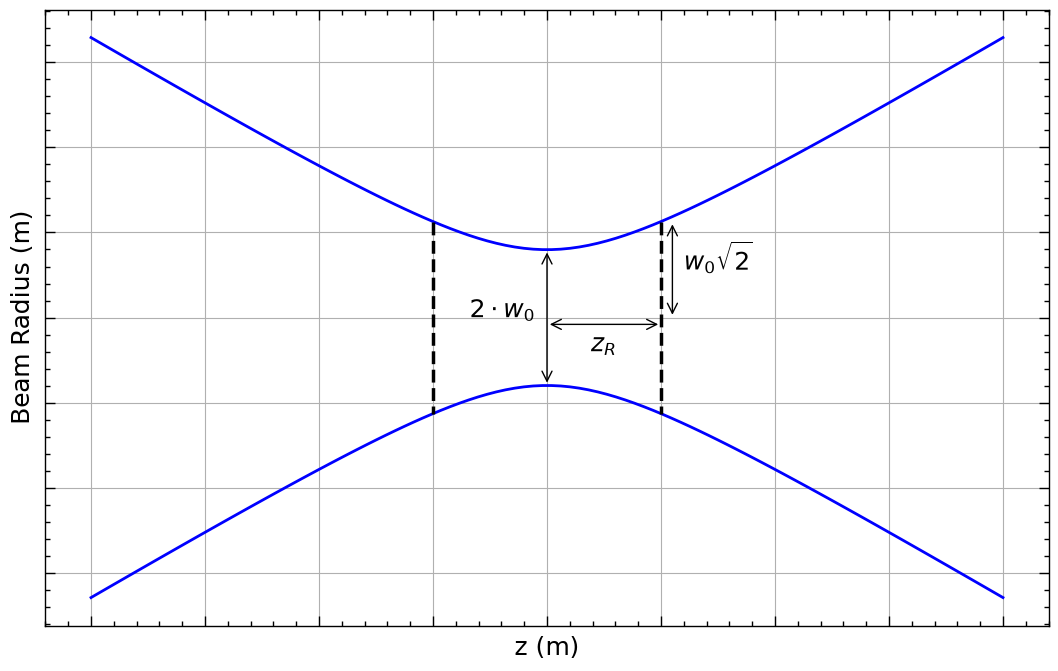

In [4]:
# create a figure containing a single set of axes
fig1, ax1 = plt.subplots(figsize=(8*1.618,8))

# plot the graph on this set of axes
ax1.plot(z1, w1, color='blue', linewidth=2)
ax1.plot(z1, -w1, color='blue', linewidth=2)

# Add central arrow indicating beam waist
ax1.annotate('', xy=(0, w0), xytext=(0, -w0),
            arrowprops=dict(arrowstyle='<->', color='black'))
ax1.text(-0.1, 0, "$2 \cdot w_0$", fontsize=18, ha='right')

# Add dashed lines and arrows at z = ±1
ax1.plot([1, 1], [w0*np.sqrt(2), -w0*np.sqrt(2)], 'k--')
ax1.plot([-1, -1], [w0*np.sqrt(2), -w0*np.sqrt(2)], 'k--')
ax1.annotate('', xy=(1, -w0/10), xytext=(0, -w0/10),
            arrowprops=dict(arrowstyle='<->', color='black'))
ax1.text(0.5, -w0/2, "$z_R$", fontsize=18, ha='center')

# Arrow and label for beam radius at z=z0
ax1.annotate('', xy=(1.1, w0*np.sqrt(2)), xytext=(1.1, 0),
            arrowprops=dict(arrowstyle='<->', color='black'))
ax1.text(1.2, w0*np.sqrt(2)/2, "$w_0 \sqrt{2}$", fontsize=18, ha='left')

# set the tick mark parameters
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# Frame and labels
ax1.set_xlabel("z (m)")
ax1.set_ylabel("Beam Radius (m)")
ax1.grid(True)
# ax1.set_title("Beam Radius vs z")
ax1.set_xticklabels([])  # Hide x-axis tick labels
ax1.set_yticklabels([])  # Hide y-axis tick labels

# Save the plot
# plt.savefig("beam_radius_plot.png")
plt.show()


## Make interactive with `matplotlib` and `ipywidgets`

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, FloatSlider

def plot_beam_unicode(w0):
    # --- Physics Calculations ---
    lam = 1.0 
    z_R = (np.pi * w0**2) / lam
    z1 = np.linspace(-4, 4, 500)
    w1 = w0 * np.sqrt(1 + (z1/z_R)**2)

    # --- Plotting ---
    fig1, ax1 = plt.subplots(figsize=(10, 6))

    # Plot the beam profile
    ax1.plot(z1, w1, color='blue', linewidth=2)
    ax1.plot(z1, -w1, color='blue', linewidth=2)

    # --- UNICODE LABELS (Instant render, looks like math) ---
    
    # Central arrow: "2 · w₀"
    ax1.annotate('', xy=(0, w0), xytext=(0, -w0),
                 arrowprops=dict(arrowstyle='<->', color='black'))
    ax1.text(-0.1, 0, "2 · w₀", fontsize=16, ha='right') 

    # Dashed lines
    ax1.plot([z_R, z_R], [w0*np.sqrt(2), -w0*np.sqrt(2)], 'k--')
    ax1.plot([-z_R, -z_R], [w0*np.sqrt(2), -w0*np.sqrt(2)], 'k--')
    
    # Arrow for z_R: "zᵣ" (using unicode subscript r)
    ax1.annotate('', xy=(z_R, -w0/10), xytext=(0, -w0/10),
                 arrowprops=dict(arrowstyle='<->', color='black'))
    ax1.text(z_R/2, -w0/2, "zᵣ", fontsize=16, ha='center')

    # Arrow for w(z_R): "w₀√2"
    ax1.annotate('', xy=(z_R + 0.1, w0*np.sqrt(2)), xytext=(z_R + 0.1, 0),
                 arrowprops=dict(arrowstyle='<->', color='black'))
    ax1.text(z_R + 0.2, w0*np.sqrt(2)/2, "w₀√2", fontsize=16, ha='left')

    # Frame and labels
    ax1.set_xlabel("z (m)")
    ax1.set_ylabel("Beam Radius")
    ax1.grid(True, alpha=0.3)
    ax1.set_xticklabels([]) 
    ax1.set_yticklabels([]) 
    
    # Lock the view
    ax1.set_xlim(-4, 4)
    ax1.set_ylim(-6, 6)

    plt.show()

# --- Slider ---
# Using unicode in the slider description too!
slider = FloatSlider(value=1.0, min=0.2, max=1.2, step=0.05, 
                     description='Waist w₀',  # <--- Unicode here too
                     continuous_update=False)

interact(plot_beam_unicode, w0=slider);

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-03_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-03.html) (direct link: [ch02-03_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-03_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.